# Figure 7 — shape improvement relative to native NISP

The main figure shows the percentage reduction in combined ellipticity-component
RMSE relative to native NISP, for diffusion (one sample), ResNet and ResNet-D5.
Each model is compared with native NISP on the same galaxies. Positive values
mean lower error; negative values mean higher error. Paired spatial-block 95%
intervals show uncertainty in the reduction itself. Fixed and adaptive moments
appear side by side, with an identical horizontal scale.

The companion summary retains native NISP, interpolation baselines, mean-of-three
diffusion, both estimators and full-population measurement success. The previous
agreement and residual-contour views are preserved in `exports/` and `revisions/`.

This is a presentation revision of the frozen `cached_shapes_v02` measurements:
all numerical results, populations, masks and checkpoints are unchanged. Native
NISP uses its original grid and validity mask, with the same angular measurement
settings as cached images. Each estimator uses the intersection of successful
JWST, native NISP and all six cached methods: 1,446 objects for fixed moments and
1,498 for adaptive moments, out of 2,118 attempted fields. All comparisons are
conditional on these successful samples; measurement failures remain reported.
These are observed cross-band ellipticities, not PSF-corrected shapes or calibrated
shear. No new inference, training, or test-set access.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style()
VERSION='v04'
DATA_VERSION='v02'
path=FIGURES/'inputs'/f'cached_shapes_{DATA_VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only']
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
with np.load(ROOT/b['arrays_path']) as f:arrays={k:f[k] for k in f.files}
names=b['methods'];labels={'native':'Native NISP','bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
print('Attempted:',len(b['object_ids']),'Common across both estimators:',b['cross_estimator_objects'])


Attempted: 2118 Common across both estimators: 1297


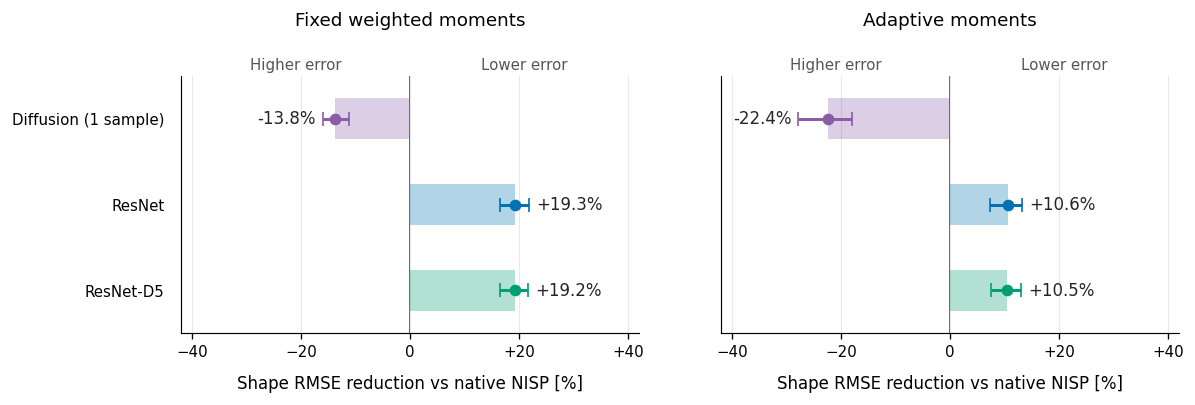

Exported: fig07_shape_improvement_v04.pdf, fig07_shape_improvement_v04.svg, fig07_shape_improvement_v04.png


In [2]:
# Main Figure 7: show the paired improvement directly.
style(10)
shown=['diffusion','legacy','direct5']
fig,axes=plt.subplots(1,2,figsize=(10.2,3.7),sharex=True,sharey=True)
y=np.arange(len(shown))
for ax,case,title in zip(axes,['fixed','adaptive'],['Fixed weighted moments','Adaptive moments']):
    ax.axvline(0,color='#555555',lw=1.1,zorder=1)
    ax.grid(axis='x',color='#E8E8E8',lw=.7,zorder=0)
    for i,name in enumerate(shown):
        record=b['native_comparison'][case][name]
        gain=record['reduction_percent'][0]
        lo,hi=record['ci95_percent'][0]
        # Index 0 combines e1/e2; these are paired intervals on the gain itself.
        rmse=b['summaries'][case]['methods'][name]['component_rmse']['mean']
        native_rmse=b['summaries'][case]['methods']['native']['component_rmse']['mean']
        assert np.isclose(gain,100*(1-rmse/native_rmse))
        ax.barh(i,gain,height=.48,color=colors[name],alpha=.30,zorder=2)
        ax.errorbar(gain,i,xerr=[[gain-lo],[hi-gain]],fmt='o',ms=6,
                    color=colors[name],ecolor=colors[name],capsize=4,lw=1.8,zorder=3)
        ax.text(hi+1.3 if gain>=0 else lo-1.3,i,f'{gain:+.1f}%',
                va='center',ha='left' if gain>=0 else 'right',fontsize=10,color='#252525')
    ax.set_title(title,pad=30)
    ax.text(.25,1.025,'Higher error',ha='center',transform=ax.transAxes,fontsize=9,color='#555555')
    ax.text(.75,1.025,'Lower error',ha='center',transform=ax.transAxes,fontsize=9,color='#555555')
    ax.set_xlim(-42,42);ax.set_xticks([-40,-20,0,20,40],['−40','−20','0','+20','+40'])
    ax.set_ylim(len(shown)-.5,-.5)
    ax.set_xlabel('Shape RMSE reduction vs native NISP [%]',labelpad=9)
axes[0].set_yticks(y,[labels[m] for m in shown])
for ax in axes:ax.tick_params(axis='y',length=0,pad=10)
fig.subplots_adjust(left=.17,right=.985,top=.78,bottom=.20,wspace=.18)
plt.show()
export(fig,f'fig07_shape_improvement_{VERSION}','07_model_shapes.ipynb',
       [path,ROOT/b['arrays_path']],
       dict(methods=shown,estimators=['fixed','adaptive'],
            metric='100*(1-RMSE_model/RMSE_native), combined e1/e2 component RMSE',
            intervals=b['gain'],population=b['population'],
            common_objects={case:b['summaries'][case]['common_successes'] for case in ['fixed','adaptive']},
            axis_limits=[-42,42],native_baseline_percent=0),
       status='Figure 7: paired shape RMSE reduction relative to native NISP')
style()


## Figure 7 caption

Reduction in observed ellipticity error relative to native NISP for diffusion
(one sample), ResNet and ResNet-D5, using fixed weighted moments (left) and
adaptive moments (right). Points show
$100(1-\mathrm{RMSE}_{\mathrm{model}}/\mathrm{RMSE}_{\mathrm{NISP}})$; bars extend
from the native-NISP baseline at zero. Positive values indicate lower shape error
and negative values higher error. Whiskers are conditional 95% intervals from
2,000 paired spatial-block bootstrap draws. Component RMSE combines both
ellipticity components as
$\sqrt{\langle(\Delta e_1^2+\Delta e_2^2)/2\rangle}$ relative to observed JWST F115W.
All model/native comparisons use the identical successful sample within each
estimator: 1,446 objects for fixed moments and 1,498 for adaptive moments, out of
2,118 attempted validation fields. Measurement success and all comparison methods
are retained in the companion diagnostic. Fixed and adaptive moments define
different shape measurements, and their samples differ. These observed cross-band
shapes include instrumental PSF and pixel-sampling differences; they are not
calibrated shear estimates.

In [3]:
print(f"Figure 7: {b['summaries']['fixed']['common_successes']:,} common successful objects / {len(b['object_ids']):,} attempted.")
rows=[]
for case in ['fixed','adaptive']:
    for name in ['native','diffusion','legacy','direct5']:
        rec=b['native_comparison'][case][name]
        rows.append(dict(estimator=case,method=labels[name],
            common_objects=b['summaries'][case]['common_successes'],
            successful_of_2118=b['summaries'][case]['success_counts'][name],
            component_rmse=rec['rmse'][0],gain_percent=rec['reduction_percent'][0],
            gain_ci95_percent=rec['ci95_percent'][0]))
display(pd.DataFrame(rows))


Figure 7: 1,446 common successful objects / 2,118 attempted.


,estimator,method,common_objects,successful_of_2118,component_rmse,gain_percent,gain_ci95_percent
0,fixed,Native NISP,1446,1741,0.201114,0.000000,"[0.0, 0.0]"
1,fixed,Diffusion (1 sample),1446,1633,0.228958,-13.844969,"[-16.03157423277367, -11.26577964635931]"
2,fixed,ResNet,1446,1786,0.162364,19.267582,"[16.591509333536603, 21.87278368654546]"
3,fixed,ResNet-D5,1446,1786,0.162494,19.203084,"[16.520554995929015, 21.64788704880936]"
4,adaptive,Native NISP,1498,1685,0.242377,0.000000,"[0.0, 0.0]"
5,adaptive,Diffusion (1 sample),1498,1678,0.296577,-22.362146,"[-27.807251658056707, -17.97281253539561]"
6,adaptive,ResNet,1498,1742,0.216657,10.611569,"[7.3468183709684, 13.219594509871527]"
7,adaptive,ResNet-D5,1498,1745,0.216849,10.532413,"[7.611552589936058, 13.020338502896005]"


## Companion diagnostic: both estimators and all attempted measurements

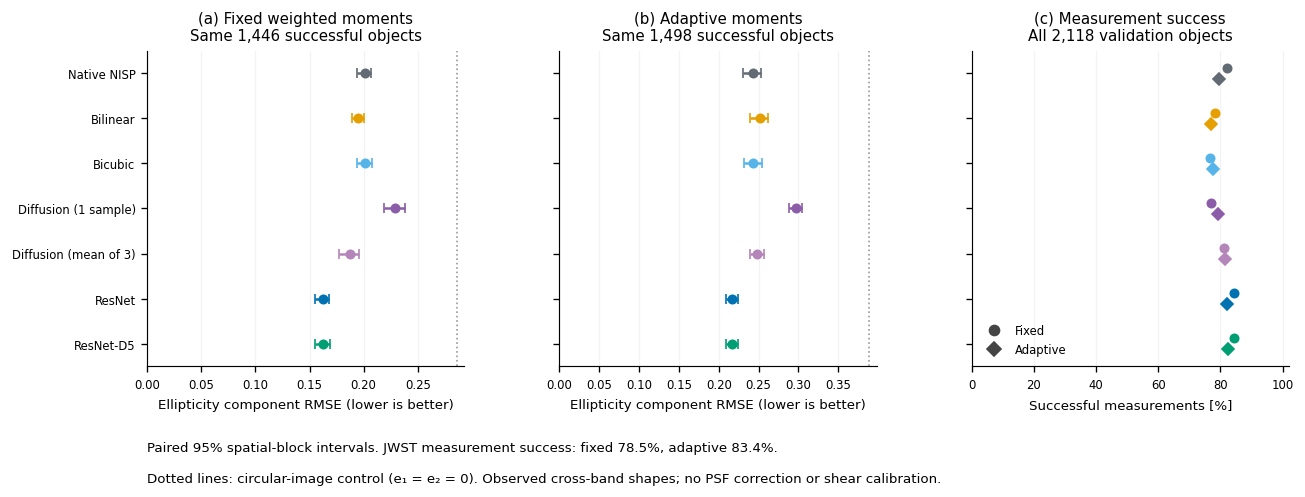

Exported: fig07_model_shapes_v04.pdf, fig07_model_shapes_v04.svg, fig07_model_shapes_v04.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v04.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v04.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v04.png')]

In [4]:
fig,axes=plt.subplots(1,3,figsize=(11.6,4.7),sharey=True)
y=np.arange(len(names))
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['(a) Fixed weighted moments','(b) Adaptive moments']):
    summary=b['summaries'][case]
    for i,name in enumerate(names):
        rec=summary['methods'][name]['component_rmse'];value=rec['mean'];lo,hi=rec['ci95']
        ax.errorbar(value,i,xerr=np.array([[value-lo],[hi-value]]),fmt='o',color=colors[name],capsize=3,ms=5)
    control=summary['methods']['round_control']['component_rmse']['mean']
    ax.axvline(control,color='#999999',ls=':',lw=1)
    ax.set_xlim(left=0)
    ax.set_xlabel('Ellipticity component RMSE (lower is better)')
    ax.set_title(f"{title}\nSame {summary['common_successes']:,} successful objects")
axes[0].set_yticks(y,[labels[m] for m in names])
for case,marker,offset in [('fixed','o',-.12),('adaptive','D',.12)]:
    for i,name in enumerate(names):
        fraction=100*b['summaries'][case]['success_counts'][name]/len(b['object_ids'])
        axes[2].plot(fraction,i+offset,marker,color=colors[name],ms=5)
axes[2].set_title('(c) Measurement success\nAll 2,118 validation objects')
axes[2].set_xlim(0,102);axes[2].set_xlabel('Successful measurements [%]')
axes[2].legend(handles=[Line2D([],[],color='#444444',marker='o',ls='',label='Fixed'),Line2D([],[],color='#444444',marker='D',ls='',label='Adaptive')],loc='lower left',frameon=False)
for ax in axes:
    ax.set_ylim(len(names)-.5,-.5);ax.grid(axis='x',alpha=.15)
fig.subplots_adjust(left=.17,right=.99,top=.81,bottom=.25,wspace=.3)
fixed_ref=100*b['summaries']['fixed']['success_counts']['target']/len(b['object_ids'])
adaptive_ref=100*b['summaries']['adaptive']['success_counts']['target']/len(b['object_ids'])
fig.text(.17,.10,f'Paired 95% spatial-block intervals. JWST measurement success: fixed {fixed_ref:.1f}%, adaptive {adaptive_ref:.1f}%.',fontsize=8)
fig.text(.17,.045,'Dotted lines: circular-image control (e₁ = e₂ = 0). Observed cross-band shapes; no PSF correction or shear calibration.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shapes_{VERSION}','07_model_shapes.ipynb',[path],
       dict(population=b['population'],fixed=b['fixed'],adaptive=b['adaptive'],summary=b['summary']),
       status='Local matched observed-shape comparison and full-denominator measurement success')


In [5]:
rows=[]
for population,summaries in [('Per-estimator common',b['summaries']),('Both estimators common',b['cross_estimator_common'])]:
    for estimator,summary in summaries.items():
        for name in names:
            rec=summary['methods'][name]
            rows.append(dict(population=population,estimator=estimator,objects=summary['common_successes'],method=labels[name],
                component_rmse=rec['component_rmse']['mean'],ci95=rec['component_rmse']['ci95'],bias_e1=rec['bias']['mean'][0],bias_e2=rec['bias']['mean'][1],
                large_error_fraction=rec['vector_error_above_0_2_fraction']['mean']))
display(pd.DataFrame(rows))


,population,estimator,objects,method,component_rmse,ci95,bias_e1,bias_e2,large_error_fraction
0,Per-estimator common,fixed,1446,Native NISP,0.201114,"[0.19428294814922256, 0.2071313152267453]",0.011173,-0.000405,0.376902
1,Per-estimator common,fixed,1446,Bilinear,0.195218,"[0.1892041880685358, 0.2004383864028548]",0.010785,0.000455,0.399723
2,Per-estimator common,fixed,1446,Bicubic,0.201446,"[0.19418894795282546, 0.2078456160897296]",0.010564,-0.000530,0.374827
3,Per-estimator common,fixed,1446,Diffusion (1 sample),0.228958,"[0.2184291798724818, 0.23781131310163514]",0.032180,-0.015698,0.429461
4,Per-estimator common,fixed,1446,Diffusion (mean of 3),0.187511,"[0.17752315863011217, 0.19618020484332216]",0.031907,-0.015020,0.352006
5,Per-estimator common,fixed,1446,ResNet,0.162364,"[0.15529346190828233, 0.16839012022839078]",0.017356,-0.000945,0.286307
6,Per-estimator common,fixed,1446,ResNet-D5,0.162494,"[0.1554486054894158, 0.16864597053879055]",0.019325,-0.000040,0.286307
7,Per-estimator common,adaptive,1498,Native NISP,0.242377,"[0.23029156356561614, 0.2531584123270412]",0.010843,-0.006433,0.550734
8,Per-estimator common,adaptive,1498,Bilinear,0.251618,"[0.23924230763094992, 0.2620319609871056]",0.012356,-0.003585,0.598798
9,Per-estimator common,adaptive,1498,Bicubic,0.243203,"[0.23100338883495103, 0.25406251889347065]",0.010900,-0.006499,0.560748


## Interpretation limits

The error bars condition on each estimator's matched successful sample. Report
full-population success fractions with the shape errors, and inspect the stricter
intersection across both estimators. Fixed and adaptive shapes use different
weights, so their absolute RMSE values have different targets. Galaxies in a
blend may contaminate both measurements; the adaptive centroid guard is not a
deblender. Mean-of-three refers to a mean image, not averaged ellipticity draws.
This cache cannot establish diffusion realization-to-realization shape scatter.
